In [1]:
import datetime
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt
import seaborn as sn

from lutils.fin.data_loader import load

In [2]:
%matplotlib widget

In [3]:
from lutils.fin.data_loader import load

In [4]:
start_date = '2024-04-25'

In [5]:
exchange = 'SHFE' # SHFE CZCE

In [6]:
price1 = 3500
price2 = 3600
price_diff = price2 - price1

In [7]:
f_symbol = 'rb2410'

c_symbol1 = 'rb2410C%s' % price1
p_symbol1 = 'rb2410P%s' % price1

c_symbol2 = 'rb2410C%s' % price2
p_symbol2 = 'rb2410P%s' % price2

In [8]:
f_df = load(exchange, f_symbol, start_date, resample='1s')

c1_df = load(exchange, c_symbol1, start_date, resample='1s')
p1_df = load(exchange, p_symbol1, start_date, resample='1s')

c2_df = load(exchange, c_symbol2, start_date, resample='1s')
p2_df = load(exchange, p_symbol2, start_date, resample='1s')

load Y:/ctp_data\2024-04-26\SHFE.rb2410.h5
load Y:/ctp_data\2024-04-29\SHFE.rb2410.h5
load Y:/ctp_data\2024-04-30\SHFE.rb2410.h5
load Y:/ctp_data\2024-04-26\SHFE.rb2410C3500.h5
load Y:/ctp_data\2024-04-29\SHFE.rb2410C3500.h5
load Y:/ctp_data\2024-04-30\SHFE.rb2410C3500.h5
load Y:/ctp_data\2024-04-26\SHFE.rb2410P3500.h5
load Y:/ctp_data\2024-04-29\SHFE.rb2410P3500.h5
load Y:/ctp_data\2024-04-30\SHFE.rb2410P3500.h5
load Y:/ctp_data\2024-04-26\SHFE.rb2410C3600.h5
load Y:/ctp_data\2024-04-29\SHFE.rb2410C3600.h5
load Y:/ctp_data\2024-04-30\SHFE.rb2410C3600.h5
load Y:/ctp_data\2024-04-26\SHFE.rb2410P3600.h5
load Y:/ctp_data\2024-04-29\SHFE.rb2410P3600.h5
load Y:/ctp_data\2024-04-30\SHFE.rb2410P3600.h5


In [9]:
fdf = f_df[['last_price', 'bid_price1', 'ask_price1']].rename(columns={'last_price': 'f_last_price', 'bid_price1': 'f_sell_price', 'ask_price1': 'f_buy_price'})

In [10]:
c1df = c1_df[['last_price', 'bid_price1', 'ask_price1']].rename(columns={'last_price': 'c1_last_price', 'bid_price1': 'c1_sell_price', 'ask_price1': 'c1_buy_price'})

In [11]:
p1df = p1_df[['last_price', 'bid_price1', 'ask_price1']].rename(columns={'last_price': 'p1_last_price', 'bid_price1': 'p1_sell_price', 'ask_price1': 'p1_buy_price'})

In [12]:
c2df = c2_df[['last_price', 'bid_price1', 'ask_price1']].rename(columns={'last_price': 'c2_last_price', 'bid_price1': 'c2_sell_price', 'ask_price1': 'c2_buy_price'})

In [13]:
p2df = p2_df[['last_price', 'bid_price1', 'ask_price1']].rename(columns={'last_price': 'p2_last_price', 'bid_price1': 'p2_sell_price', 'ask_price1': 'p2_buy_price'})

In [14]:
fdf.shape

(54911, 3)

In [15]:
df = fdf.merge(c1df, how='left', left_index=True, right_index=True)
df = df.merge(p1df, how='left', left_index=True, right_index=True)

df = df.merge(c2df, how='left', left_index=True, right_index=True)
df = df.merge(p2df, how='left', left_index=True, right_index=True)

In [16]:
df = df.ffill()

In [17]:
df.head()

,f_last_price,f_sell_price,f_buy_price,c1_last_price,c1_sell_price,c1_buy_price,p1_last_price,p1_sell_price,p1_buy_price,c2_last_price,c2_sell_price,c2_buy_price,p2_last_price,p2_sell_price,p2_buy_price
datetime,,,,,,,,,,,,,,,
2024-04-26 09:00:00,3653.0,3653.0,3654.0,230.5,142.0,1.797693e+308,81.0,79.5,80.5,170.0,158.0,211.0,122.0,120.0,125.5
2024-04-26 09:00:01,3654.0,3654.0,3655.0,230.5,142.0,1.797693e+308,81.0,79.5,80.5,170.0,158.0,211.0,120.0,119.0,120.5
2024-04-26 09:00:02,3654.0,3654.0,3655.0,230.5,212.0,2.475000e+02,79.5,78.5,80.5,170.0,158.5,182.5,120.0,119.0,120.5
2024-04-26 09:00:03,3655.0,3655.0,3656.0,230.5,212.0,2.475000e+02,79.5,78.5,80.5,170.0,158.5,182.5,120.0,119.0,120.5
2024-04-26 09:00:04,3656.0,3655.0,3656.0,230.5,227.0,2.355000e+02,79.5,78.0,80.5,170.0,165.5,173.5,119.0,115.5,120.5


In [18]:
df = df.dropna()

In [19]:
df['negative_last_price'] = df['c1_last_price'] - df['p1_last_price'] - df['c2_last_price'] + df['p2_last_price'] - price_diff

df['negative'] = df['c1_buy_price'] - df['p1_sell_price'] - df['c2_sell_price'] + df['p2_buy_price'] - price_diff
df['positive'] = df['c2_buy_price'] - df['p2_sell_price'] - df['c1_sell_price'] + df['p1_buy_price'] + price_diff

In [20]:
df = df[(df.negative > -1000000) & (df.negative < 1000000)]
df = df[(df.positive > -1000000) & (df.positive < 1000000)]

In [21]:
df.head(5)

,f_last_price,f_sell_price,f_buy_price,c1_last_price,c1_sell_price,c1_buy_price,p1_last_price,p1_sell_price,p1_buy_price,c2_last_price,c2_sell_price,c2_buy_price,p2_last_price,p2_sell_price,p2_buy_price,negative_last_price,negative,positive
datetime,,,,,,,,,,,,,,,,,,
2024-04-26 09:00:02,3654.0,3654.0,3655.0,230.5,212.0,247.5,79.5,78.5,80.5,170.0,158.5,182.5,120.0,119.0,120.5,1.000000e+00,31.0,32.0
2024-04-26 09:00:03,3655.0,3655.0,3656.0,230.5,212.0,247.5,79.5,78.5,80.5,170.0,158.5,182.5,120.0,119.0,120.5,1.000000e+00,31.0,32.0
2024-04-26 09:00:04,3656.0,3655.0,3656.0,230.5,227.0,235.5,79.5,78.0,80.5,170.0,165.5,173.5,119.0,115.5,120.5,1.421085e-14,12.5,11.5
2024-04-26 09:00:05,3656.0,3656.0,3657.0,230.5,227.0,232.0,79.5,78.0,80.5,170.0,168.0,170.0,119.0,117.5,120.5,1.421085e-14,6.5,6.0
2024-04-26 09:00:06,3656.0,3656.0,3657.0,230.5,227.0,232.0,79.5,78.0,80.5,170.0,168.0,170.0,119.0,117.5,120.5,1.421085e-14,6.5,6.0


In [22]:
# _df[150:200]

In [23]:
# plt.close()

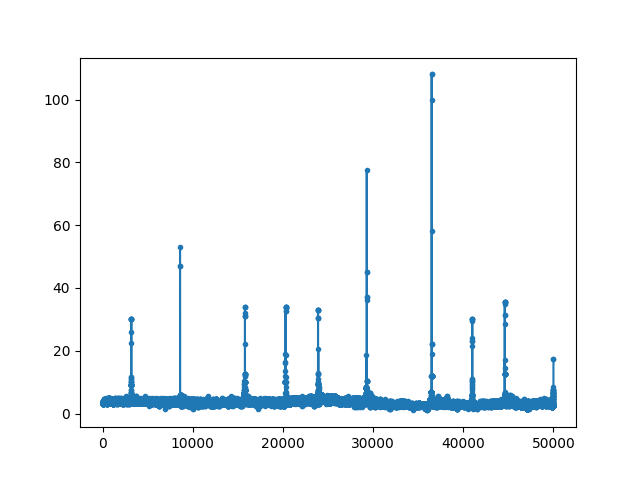

In [24]:
plt.close()
_df = df.iloc[-50000:]
# plt.scatter(_df.index, _df.negative, marker='.')

plt.plot(_df.negative.values, marker='.')

In [35]:
# plt.close()

In [34]:
# sn.displot(df.negative.values, kind='kde')

In [117]:
plt.close()

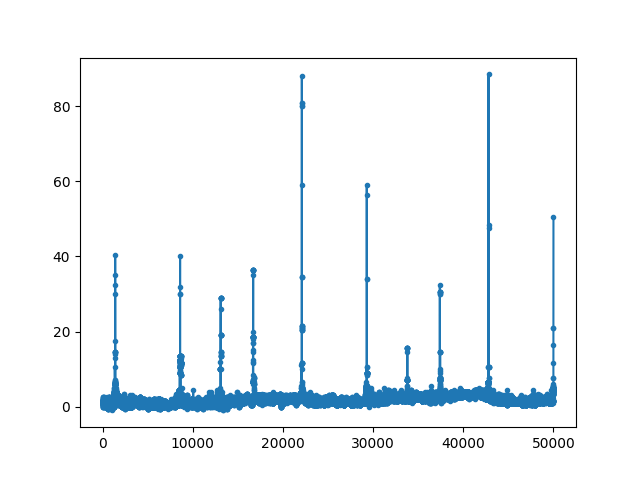

In [118]:
# plt.plot(df.positive.values)

_df = df.iloc[-50000:]
# plt.scatter(_df.index, _df.positive, marker='.')
plt.plot(_df.positive.values, marker='.')

In [104]:
plt.close()

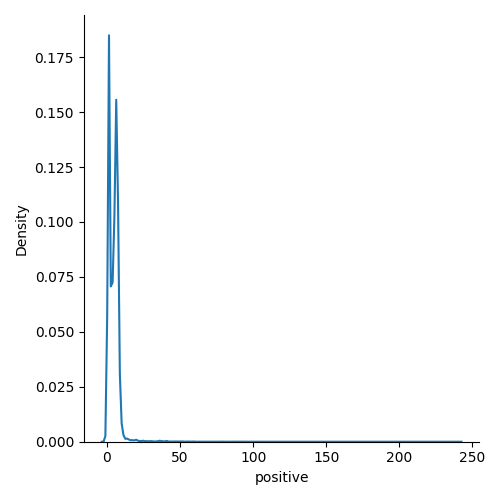

In [105]:
sn.displot(df.positive, kind='kde')

In [25]:
_df = df.iloc[-500000:]
# _df['buy_time'] = _df.positive - _df.negative
_df = _df.assign(buy_time = _df.positive - _df.negative)
# _df.loc[_df['buy_time'] < 0] = 0

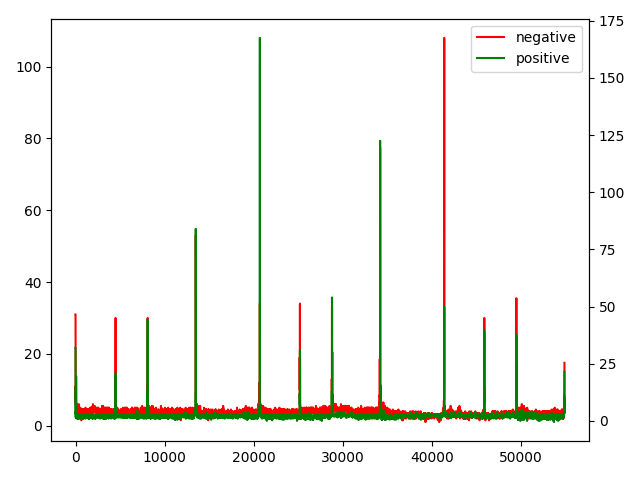

In [26]:
plt.close()

fig, ax1 = plt.subplots()

ax1.plot(_df.negative.values, label='negative', color='r')
# ax1.plot(_df.buy_time.values, label='buy_time', marker='.', color='y')

ax2 = ax1.twinx()
ax2.plot(_df.positive.values, label='positive', color='g')
# ax2.plot(_df.negative_last_price, label='negative_last_price', color='g')
# ax2.plot(_df.f_last_price.values, label='f_last_price', color='g')


lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

fig.tight_layout()
plt.show()

In [26]:
rb2410_df = pd.read_hdf('D:/code/python/fin/strategy1/x/rb2410.h5')

In [27]:
rb2410_df.columns

Index(['rb2410', 'rb2410C3600', 'rb2410P3600', 'rb2410C3500', 'rb2410P3500',
       'rb2410C3600_bid_price1', 'rb2410C3600_ask_price1',
       'rb2410P3600_bid_price1', 'rb2410P3600_ask_price1',
       'rb2410C3500_bid_price1', 'rb2410C3500_ask_price1',
       'rb2410P3500_bid_price1', 'rb2410P3500_ask_price1', 'rb2410_3600',
       'rb2410_3600_positive', 'rb2410_3600_negative',
       'rb2410_3600_positive_spread', 'rb2410_3500', 'rb2410_3500_positive',
       'rb2410_3500_negative', 'rb2410_3500_positive_spread',
       'rb2410_bid_price1', 'rb2410_ask_price1', 'rb2410_3600_negative_spread',
       'rb2410_3500_negative_spread'],
      dtype='object')

In [28]:
__df1 = rb2410_df[['rb2410_3600_negative_spread','rb2410_3500_negative_spread']]

In [29]:
__df2 = df.loc['2024-04-30 13:38:09':,['negative', 'positive']]

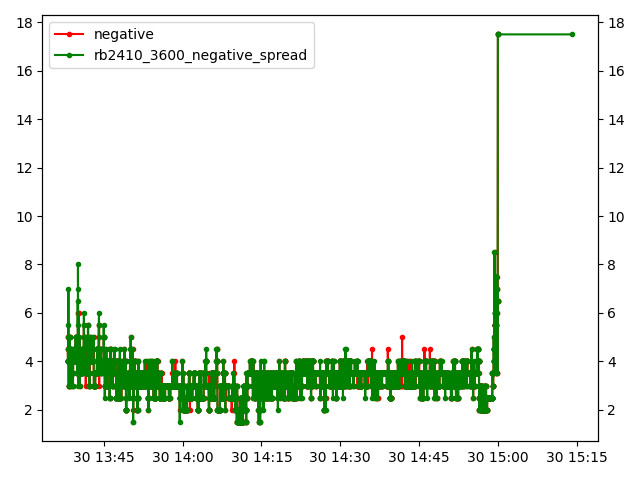

In [30]:
plt.close()

fig, ax1 = plt.subplots()

ax1.plot(__df2.negative, label='negative', color='r', marker='.')
# ax1.plot(_df.buy_time.values, label='buy_time', marker='.', color='y')

ax2 = ax1.twinx()
ax2.plot(__df1.rb2410_3600_negative_spread, label='rb2410_3600_negative_spread', color='g', marker='.')
# ax2.plot(_df.negative_last_price, label='negative_last_price', color='g')
# ax2.plot(_df.f_last_price.values, label='f_last_price', color='g')


lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

fig.tight_layout()
plt.show()